<a href="https://colab.research.google.com/github/zubaeteee20210205109-droid/Thesis/blob/main/An_Intelligent_Hybrid_EfficientNetV2B0%E2%80%93Transformer_Architecture_for_Early_Detection_of_Arsenicosis_Skin_Disease.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
# ============================================================
# CHECK GPU
# ============================================================

import tensorflow as tf

print("="*60)
print("TensorFlow Version :", tf.__version__)
print("="*60)

print("Built with CUDA :", tf.test.is_built_with_cuda())
print("GPU Available   :", tf.test.is_gpu_available())

print("="*60)

gpus = tf.config.list_physical_devices("GPU")

print("Available GPUs :", gpus)

if gpus:

    print("\n✅ GPU DETECTED")

    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)

    print("GPU Name :", tf.config.experimental.get_device_details(gpus[0]).get("device_name"))

else:

    print("\n❌ NO GPU DETECTED")
    print("TensorFlow is running on CPU.")

print("="*60)

TensorFlow Version : 2.20.0
Built with CUDA : True
GPU Available   : True
Available GPUs : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

✅ GPU DETECTED
GPU Name : Tesla T4


In [6]:
!nvidia-smi

Sun Jul  5 17:47:23 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   69C    P0             32W /   70W |     105MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [7]:
# ============================================================
# BLOCK 1 : IMPORT LIBRARIES
# ============================================================

import os
import json
import pickle
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.efficientnet_v2 import preprocess_input

from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    auc,
    precision_recall_curve
)

from sklearn.preprocessing import label_binarize

# ============================================================
# RANDOM SEED
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [8]:
import os
import shutil

SOURCE = "/content/drive/MyDrive/ArsenicSkinImage(BD)/Split_Dataset"
DESTINATION = "/content/Split_Dataset"

if not os.path.exists(DESTINATION):

    print("Copying dataset to local storage...")

    shutil.copytree(
        SOURCE,
        DESTINATION
    )

    print("Dataset copied successfully!")

else:
    print("Dataset already exists in local storage.")

Copying dataset to local storage...
Dataset copied successfully!


In [9]:
# ============================================================
# BLOCK 2 : DATA GENERATORS
# ============================================================

train_path = "/content/Split_Dataset/Train"

val_path = "/content/Split_Dataset/Validation"

test_path = "/content/Split_Dataset/Test"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# ============================================================
# ImageDataGenerator
# No additional augmentation because the dataset
# is already augmented.
# ============================================================

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

validation_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

# ============================================================
# Train Generator
# ============================================================

train_generator = train_datagen.flow_from_directory(
    train_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True
)

# ============================================================
# Validation Generator
# ============================================================

validation_generator = validation_datagen.flow_from_directory(
    val_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

# ============================================================
# Test Generator
# ============================================================

test_generator = test_datagen.flow_from_directory(
    test_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

NUM_CLASSES = train_generator.num_classes

print("=" * 60)
print("Number of Classes :", NUM_CLASSES)
print("Class Indices     :", train_generator.class_indices)
print("=" * 60)

print("Train Samples      :", train_generator.samples)
print("Validation Samples :", validation_generator.samples)
print("Test Samples       :", test_generator.samples)

Found 6224 images belonging to 2 classes.
Found 1334 images belonging to 2 classes.
Found 1334 images belonging to 2 classes.
Number of Classes : 2
Class Indices     : {'infected': 0, 'not_infected': 1}
Train Samples      : 6224
Validation Samples : 1334
Test Samples       : 1334


In [10]:
# ============================================================
# BLOCK 3 : CLASS WEIGHTS
# ============================================================

labels = train_generator.classes

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(labels),
    y=labels
)

class_weights = dict(enumerate(class_weights))

print("=" * 60)
print("Class Weights")
print(class_weights)
print("=" * 60)

Class Weights
{0: np.float64(1.0), 1: np.float64(1.0)}


In [11]:
# ============================================================
# BLOCK 4 : TRANSFORMER BLOCK
# ============================================================

def transformer_block(x):

    attention = layers.MultiHeadAttention(
        num_heads=4,
        key_dim=x.shape[-1] // 4
    )(x, x)

    x1 = layers.Add()([x, attention])
    x1 = layers.LayerNormalization(epsilon=1e-6)(x1)

    ffn = layers.Dense(
        x.shape[-1] * 2,
        activation="gelu"
    )(x1)

    ffn = layers.Dense(
        x.shape[-1]
    )(ffn)

    x2 = layers.Add()([x1, ffn])
    x2 = layers.LayerNormalization(epsilon=1e-6)(x2)

    return x2

In [12]:
# ============================================================
# BLOCK 5 : BUILD MODEL
# ============================================================

def build_model(num_classes):

    inputs = layers.Input(shape=(224,224,3))

    base_model = tf.keras.applications.EfficientNetV2B0(
        include_top=False,
        weights="imagenet",
        input_tensor=inputs
    )

    # Fine-tune only the last 20 layers
    base_model.trainable = True

    for layer in base_model.layers[:-20]:
        layer.trainable = False

    x = base_model.output

    h = x.shape[1]
    w = x.shape[2]
    c = x.shape[3]

    num_patches = h * w

    x = layers.Reshape((num_patches, c))(x)

    positions = tf.range(start=0, limit=num_patches, delta=1)

    position_embedding = layers.Embedding(
        input_dim=num_patches,
        output_dim=c
    )(positions)

    x = x + position_embedding

    # Transformer Block 1
    x = transformer_block(x)

    # Transformer Block 2
    x = transformer_block(x)

    x = layers.GlobalAveragePooling1D()(x)

    x = layers.Dense(
        512,
        activation="relu"
    )(x)

    x = layers.Dropout(0.40)(x)

    x = layers.Dense(
        256,
        activation="relu"
    )(x)

    x = layers.Dropout(0.30)(x)

    outputs = layers.Dense(
        num_classes,
        activation="softmax"
    )(x)

    model = models.Model(inputs, outputs)

    return model


model = build_model(NUM_CLASSES)

model.summary()

24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          0 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ normalization[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │      4,608 │ stem_activation[… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_bn  │ (None, 112, 112,  │         64 │ block1a_project_… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_ac… │ (None, 112, 112,  │          0 │ block1a_project_… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_conv │ (None, 56, 56,    │      9,216 │ block1a_project_… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_bn   │ (None, 56, 56,    │        256 │ block2a_expand_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_act… │ (None, 56, 56,    │          0 │ block2a_expand_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_project_co… │ (None, 56, 56,    │      2,048 │ block2a_expand_a… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_project_bn  │ (None, 56, 56,    │        128 │ block2a_project_… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2b_expand_conv │ (None, 56, 56,    │     36,864 │ block2a_project_… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2b_expand_bn   │ (None, 56, 56,    │        512 │ block2b_expand_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2b_expand_act… │ (None, 56, 56,    │          0 │ block2b_expand_b

 Total params: 32,949,586 (125.69 MB)

 Trainable params: 27,848,114 (106.23 MB)

 Non-trainable params: 5,101,472 (19.46 MB)

In [13]:
# ============================================================
# BLOCK 6 : COMPILE MODEL
# ============================================================

optimizer = tf.keras.optimizers.AdamW(
    learning_rate=3e-4,
    weight_decay=1e-4
)

model.compile(
    optimizer=optimizer,
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


In [14]:
# ============================================================
# BLOCK 7 : CALLBACKS
# ============================================================

import os
import json

SAVE_DIR = "/content/drive/MyDrive/Thesis_Model"

os.makedirs(SAVE_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(SAVE_DIR, "Best_Model.keras")
FINAL_MODEL_PATH = os.path.join(SAVE_DIR, "Final_Model.keras")

HISTORY_PKL = os.path.join(SAVE_DIR, "history.pkl")
HISTORY_CSV = os.path.join(SAVE_DIR, "history.csv")

CSV_LOG = os.path.join(SAVE_DIR, "training_log.csv")

CLASS_INDEX = os.path.join(SAVE_DIR, "class_indices.json")

# -------------------------------------------------------
# Save class names
# -------------------------------------------------------

with open(CLASS_INDEX, "w") as f:
    json.dump(train_generator.class_indices, f)

print("Class indices saved.")

# -------------------------------------------------------
# Callbacks
# -------------------------------------------------------

callbacks_list = [

    callbacks.ModelCheckpoint(

        filepath=BEST_MODEL_PATH,

        monitor="val_accuracy",

        mode="max",

        save_best_only=True,

        verbose=1

    ),

    callbacks.EarlyStopping(

        monitor="val_loss",

        patience=5,

        restore_best_weights=True,

        verbose=1

    ),

    callbacks.ReduceLROnPlateau(

        monitor="val_loss",

        factor=0.5,

        patience=3,

        min_lr=1e-6,

        verbose=1

    ),

    callbacks.CSVLogger(

        CSV_LOG,

        append=False

    )

]

print("Callbacks Ready.")

Class indices saved.
Callbacks Ready.


In [15]:
# ============================================================
# BLOCK 8 : TRAIN MODEL
# ============================================================

history = model.fit(

    train_generator,

    validation_data=validation_generator,

    epochs=25,

    class_weight=class_weights,

    callbacks=callbacks_list,

    verbose=1

)

Epoch 1/25
195/195 ━━━━━━━━━━━━━━━━━━━━ 0s 336ms/step - accuracy: 0.8545 - loss: 0.3829
Epoch 1: val_accuracy improved from None to 0.98876, saving model to /content/drive/MyDrive/Thesis_Model/Best_Model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Thesis_Model/Best_Model.keras
195/195 ━━━━━━━━━━━━━━━━━━━━ 151s 496ms/step - accuracy: 0.9166 - loss: 0.2426 - val_accuracy: 0.9888 - val_loss: 0.0447 - learning_rate: 3.0000e-04
Epoch 2/25
195/195 ━━━━━━━━━━━━━━━━━━━━ 0s 198ms/step - accuracy: 0.9702 - loss: 0.0950
Epoch 2: val_accuracy did not improve from 0.98876
195/195 ━━━━━━━━━━━━━━━━━━━━ 56s 227ms/step - accuracy: 0.9700 - loss: 0.1024 - val_accuracy: 0.9880 - val_loss: 0.0580 - learning_rate: 3.0000e-04
Epoch 3/25
195/195 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step - accuracy: 0.9745 - loss: 0.0958
Epoch 3: val_accuracy did not improve from 0.98876
195/195 ━━━━━━━━━━━━━━━━━━━━ 46s 235ms/step - accuracy: 0.9743 - loss: 0.0890 - val_accuracy: 0.9858 - val_loss: 0.0332 - learn

In [16]:
BEST_MODEL_PATH = "/content/drive/MyDrive/Thesis_Model/Best_Model.keras"

model = tf.keras.models.load_model(BEST_MODEL_PATH)

print("Best model loaded successfully.")

Best model loaded successfully.


In [17]:
test_loss, test_accuracy = model.evaluate(
    test_generator,
    verbose=1
)

print("\n" + "="*50)
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy*100:.2f}%")
print("="*50)

42/42 ━━━━━━━━━━━━━━━━━━━━ 21s 246ms/step - accuracy: 0.9903 - loss: 0.0309

Test Loss     : 0.0309
Test Accuracy : 99.03%


In [18]:
# ============================================================
# BLOCK 12 : PREDICTIONS
# ============================================================

import numpy as np

# Reset generator
test_generator.reset()

# Predict probabilities
y_pred_prob = model.predict(
    test_generator,
    verbose=1
)

# Predicted class
y_pred = np.argmax(y_pred_prob, axis=1)

# True class
y_true = test_generator.classes

# Class Names
class_names = list(test_generator.class_indices.keys())

print("Prediction Completed Successfully.")

42/42 ━━━━━━━━━━━━━━━━━━━━ 20s 311ms/step
Prediction Completed Successfully.


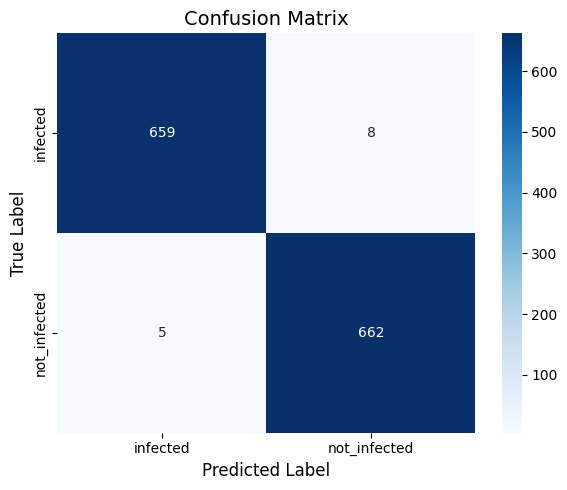

In [28]:
# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)
plt.title("Confusion Matrix", fontsize=14)

plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/Thesis_Model/Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [20]:
# ============================================================
# BLOCK 14 : CLASSIFICATION REPORT
# ============================================================

print("="*60)
print("Classification Report")
print("="*60)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4
    )
)

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true,
    y_pred,
    average='weighted'
)

recall = recall_score(
    y_true,
    y_pred,
    average='weighted'
)

f1 = f1_score(
    y_true,
    y_pred,
    average='weighted'
)

print("\n"+"="*60)
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print("="*60)

Classification Report
              precision    recall  f1-score   support

    infected     0.9925    0.9880    0.9902       667
not_infected     0.9881    0.9925    0.9903       667

    accuracy                         0.9903      1334
   macro avg     0.9903    0.9903    0.9903      1334
weighted avg     0.9903    0.9903    0.9903      1334


Accuracy : 0.9903
Precision: 0.9903
Recall   : 0.9903
F1-score : 0.9903


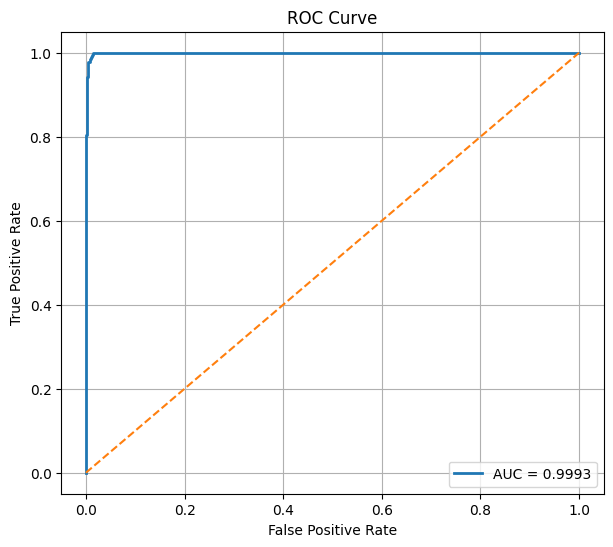

In [21]:
# ============================================================
# BLOCK 15 : ROC CURVE
# ============================================================

from sklearn.metrics import roc_curve, auc

# Positive class probability
y_score = y_pred_prob[:,1]

fpr, tpr, _ = roc_curve(y_true, y_score)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7,6))

plt.plot(
    fpr,
    tpr,
    lw=2,
    label=f"AUC = {roc_auc:.4f}"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle='--'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")

plt.grid(True)

plt.show()

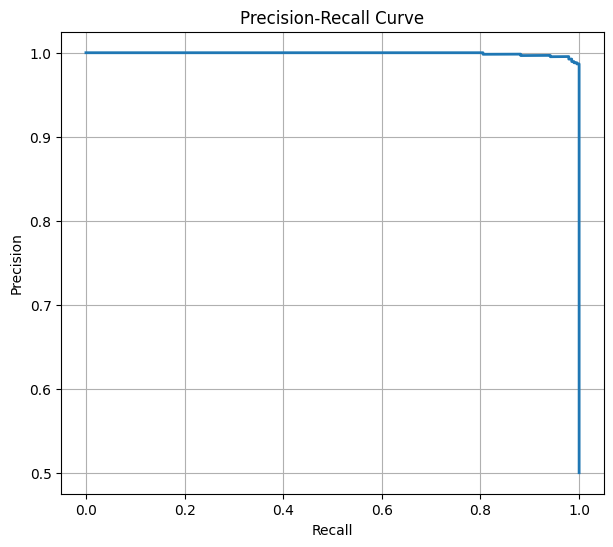

In [22]:
# ============================================================
# BLOCK 16 : PRECISION-RECALL CURVE
# ============================================================

precision_curve, recall_curve, _ = precision_recall_curve(
    y_true,
    y_score
)

plt.figure(figsize=(7,6))

plt.plot(
    recall_curve,
    precision_curve,
    linewidth=2
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")

plt.grid(True)

plt.show()

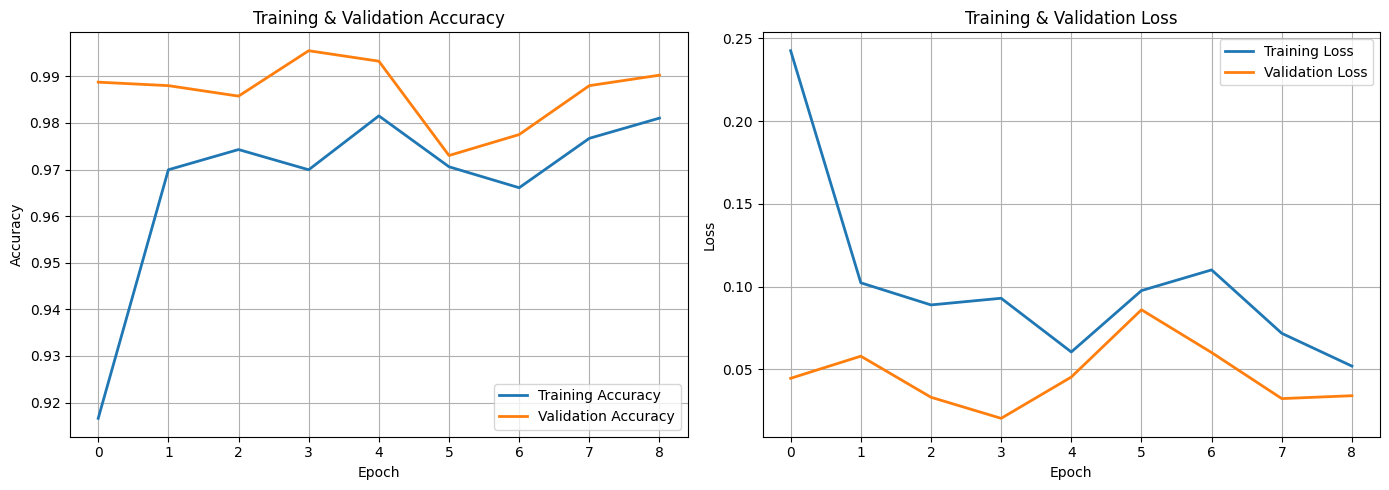

In [24]:
# ============================================================
# BLOCK 17 : TRAINING CURVES (SUBPLOTS)
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14,5))

# Accuracy
axes[0].plot(history.history['accuracy'], label='Training Accuracy', linewidth=2)
axes[0].plot(history.history['val_accuracy'], label='Validation Accuracy', linewidth=2)

axes[0].set_title("Training & Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Loss
axes[1].plot(history.history['loss'], label='Training Loss', linewidth=2)
axes[1].plot(history.history['val_loss'], label='Validation Loss', linewidth=2)

axes[1].set_title("Training & Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [25]:
# ============================================================
# BLOCK 18 : MEDICAL PERFORMANCE METRICS
# ============================================================

from sklearn.metrics import (
    confusion_matrix,
    balanced_accuracy_score,
    matthews_corrcoef,
    cohen_kappa_score
)

cm = confusion_matrix(y_true, y_pred)

TN, FP, FN, TP = cm.ravel()

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

specificity = TN / (TN + FP)

sensitivity = TP / (TP + FN)

balanced_acc = balanced_accuracy_score(
    y_true,
    y_pred
)

mcc = matthews_corrcoef(
    y_true,
    y_pred
)

kappa = cohen_kappa_score(
    y_true,
    y_pred
)

# ------------------------------------------------------------
# Print
# ------------------------------------------------------------

print("="*60)
print("Medical Evaluation Metrics")
print("="*60)

print(f"Sensitivity (Recall/TPR) : {sensitivity:.4f}")

print(f"Specificity (TNR)        : {specificity:.4f}")

print(f"Balanced Accuracy        : {balanced_acc:.4f}")

print(f"Matthews Corrcoef (MCC)  : {mcc:.4f}")

print(f"Cohen's Kappa            : {kappa:.4f}")

print("="*60)

Medical Evaluation Metrics
Sensitivity (Recall/TPR) : 0.9925
Specificity (TNR)        : 0.9880
Balanced Accuracy        : 0.9903
Matthews Corrcoef (MCC)  : 0.9805
Cohen's Kappa            : 0.9805


In [26]:
# ============================================================
# BLOCK 19 : SAVE RESULTS
# ============================================================

results = pd.DataFrame({

    "Metric":[

        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "Sensitivity",
        "Specificity",
        "Balanced Accuracy",
        "MCC",
        "Cohen Kappa",
        "Test Loss"

    ],

    "Value":[

        accuracy,
        precision,
        recall,
        f1,
        sensitivity,
        specificity,
        balanced_acc,
        mcc,
        kappa,
        test_loss

    ]

})

results.to_excel(
    "/content/drive/MyDrive/Thesis_Model/Performance_Metrics.xlsx",
    index=False
)

print(results)

              Metric     Value
0           Accuracy  0.990255
1          Precision  0.990265
2             Recall  0.990255
3           F1-score  0.990255
4        Sensitivity  0.992504
5        Specificity  0.988006
6  Balanced Accuracy  0.990255
7                MCC  0.980520
8        Cohen Kappa  0.980510
9          Test Loss  0.030893
